For Dr. Tseng:

The important cell is still `ExperimentConfig`. This version runs an
**end-to-end learning curve**: the backbone, bridge, and head all train from
scratch at each training-set size, so the quantum head is not reading a
representation that was optimized for a classical readout.

Three curves, all sharing the identical `QuantumReadyBottleneck(384 -> n_qubits)`
bridge and differing only after it:

| `head_kind` | head |
| --- | --- |
| `linear` | `Linear(n_qubits, 2)` -- the plain baseline |
| `classical` | `Linear(n_qubits, out_dim) + Tanh + LayerNorm + Linear(out_dim, 2)` |
| `quantum` | data re-uploading VQC + `LayerNorm` + `Linear(out_dim, 2)` |

`classical` and `quantum` are matched on parameter count (72 vs 70 at
`n_qubits=4, q_depth=4`) and on output width, so any difference between them is
attributable to the circuit rather than to capacity.

Changes from the previous version, all flagged in comments below:
1. `QMLHead` now uses data re-uploading with trainable input scales, RZ+RY
   rotations, and ZZ correlator measurements (10 outputs instead of 4).
2. Circuit parameters get their own learning rate and zero weight decay.
3. `early_stopping_patience` raised from 1 to 6.

Pip installations

In [ ]:
!pip install -qq numpy
!pip install -qq pandas
!pip install -qq torch
!pip install -qq qiskit
!pip install -qq pennylane
!pip install -qq matplotlib

dasdf

Imports

In [ ]:
from __future__ import annotations

import argparse
import gc
import math
import random
from dataclasses import dataclass, replace
from pathlib import Path
from typing import Callable, Sequence
import time

import numpy as np
import pandas as pd
import torch
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedKFold
from torch import Tensor, nn
from torch.nn import functional as F
from torch.utils.data import DataLoader, TensorDataset


from sklearn.datasets import make_circles
from sklearn.datasets import make_blobs
from sklearn.datasets import make_moons

import matplotlib.pyplot as plt

import torch.nn as nn

import pennylane as qml

In [ ]:
#connecting to google drive because I don't want to do this over and over again
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


Features and engineered features

In [ ]:
TARGET = "Heart Disease"
ID_COLUMN = "id"
BASE_FEATURES = (
    "Age",
    "Sex",
    "Chest pain type",
    "BP",
    "Cholesterol",
    "FBS over 120",
    "EKG results",
    "Max HR",
    "Exercise angina",
    "ST depression",
    "Slope of ST",
    "Number of vessels fluro",
    "Thallium",
)

#we're multiplying this against orig to get new values that we can give to each datapoint. We're not multiplying against train to avoid direct leakage.

STATISTICS = ("mean", "median", "std", "skew", "count")

#replicable randomseeder
def seed_everything(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


#turns target from Absence/Presence to 0/1
def map_binary_target(series: pd.Series, name: str) -> pd.Series:
    mapped = series.map({"Absence": 0, "Presence": 1})
    if mapped.isna().any():
        bad_values = sorted(map(str, series[mapped.isna()].drop_duplicates()))
        raise ValueError(f"Unexpected values (not '0 or 1'-able) in {name}: {bad_values}")
    return mapped.astype(np.int64)


# Add engineered features based on pre-ai generated features (original notebook does it)
def add_engineered_features(data: pd.DataFrame, original: pd.DataFrame, base_features: Sequence[str] = BASE_FEATURES, target: str = TARGET,) -> pd.DataFrame:
    """Reproduce cell 6 of the source notebook.

    The target statistics come only from the separate, small original data set.
    They must not be recomputed from the competition training target outside a
    fold, because doing so would leak validation labels.
    """

    result = data.copy()
    global_fill = {
        "mean": float(original[target].mean()),
        "median": float(original[target].median()),
        "std": 0.0,
        "skew": 0.0,
        "count": 0.0,
    }

    #adds new features to competition dataset by calculating values from original dataset.
    for column in base_features:
        #here begins the 500 raise errors if
        if column not in original.columns:
            raise KeyError(f"{column!r} is missing from the original data set.")

        grouped = (original.groupby(column)[target].agg(list(STATISTICS)).reset_index())

        renamed = {stat: f"orig_{column}_{stat}" for stat in STATISTICS}
        grouped = grouped.rename(columns=renamed)
        result = result.merge(grouped, on=column, how="left", validate="many_to_one")

        for stat, fill_value in global_fill.items():
            feature_name = renamed[stat]
            result[feature_name] = result[feature_name].fillna(fill_value)

    return result



def prepare_project_frames(train: pd.DataFrame,test: pd.DataFrame,original: pd.DataFrame) -> tuple[pd.DataFrame, np.ndarray, pd.DataFrame]:
    """Return the notebook's 78 string-valued fields and binary target."""

    required_train = {ID_COLUMN, TARGET, *BASE_FEATURES}
    required_test = {ID_COLUMN, *BASE_FEATURES}
    required_original = {TARGET, *BASE_FEATURES}
    for frame_name, frame, required in (("train", train, required_train),("test", test, required_test),("original", original, required_original),):

        missing = sorted(required.difference(frame.columns))
        if missing:
            raise KeyError(f"{frame_name} is missing columns: {missing}")

    train = train.copy()
    original = original.copy()
    train[TARGET] = map_binary_target(train[TARGET], "train target")
    original[TARGET] = map_binary_target(original[TARGET], "original target")

    train_features = add_engineered_features(train, original)
    test_features = add_engineered_features(test, original)

    x = train_features.drop(columns=[ID_COLUMN, TARGET])
    x_test = test_features.drop(columns=[ID_COLUMN])
    y = train_features[TARGET].to_numpy(dtype=np.int64, copy=True)


    expected_features = len(BASE_FEATURES) * (1 + len(STATISTICS))
    if x.shape[1] != expected_features or x_test.shape[1] != expected_features:
        raise AssertionError(
            f"Expected {expected_features} features; got {x.shape[1]} and "
            f"{x_test.shape[1]}"
        )
    if list(x.columns) != list(x_test.columns):
        raise AssertionError("Train and test feature columns are not aligned")

    # We are preserving the original notebook's choice of making all features into categories, even normal numbers.
    for column in x.columns:
        x[column] = x[column].astype(str)
        x_test[column] = x_test[column].astype(str)

    return x, y, x_test

## Experiment configuration

`train_subsample` is the knob the learning curve turns. It caps the number of
rows in each fold's *training* partition; validation stays whole so the OOF
score is always computed over the full split.

The fold vocabulary is fitted on the subsample, not the full partition. That is
the honest choice for a sample-efficiency claim, but it is also why the sweep
starts at 2,000 rather than 250: there are 78 categorical features here, and
below roughly a thousand rows most validation and test categories fall through
to the unknown code 0, so you would be measuring vocabulary collapse instead of
learning.

In [ ]:
@dataclass(frozen=True)
class ExperimentConfig:
    """Settings copied from the source Kaggle notebook, plus the sweep knobs."""

    n_splits: int = 5
    ensemble_size: int = 4
    max_epochs: int = 30
    min_epochs: int = 5
    batch_size: int = 256
    eval_batch_size: int = 4096

    # --- learning curve ---
    # Rows per fold's TRAINING partition. None -> use the whole partition.
    train_subsample: int | None = None
    learning_curve_sizes: tuple[int | None, ...] = (
        50, 100, 150, 200, 250, 300, 350, 400, 450, 500, 550, 600, 650, 700, 750, 800, 850, 900, 950, 1000, 1050, 1100, 1150, 1200, 1250, 1300, 1350, 1400, 1450, 1500
    )
    learning_curve_heads: tuple[str, ...] = ("quantum", "classical")
    # Early stopping runs on a fixed subsample of validation; the reported OOF
    # always uses the full split. At small train sizes a full validation pass
    # costs more than a training epoch.
    validation_subsample: int = 20_000

    # --- quantum head ---
    n_qubits: int = 4
    q_depth: int = 4
    use_correlators: bool = True     # measure <Z_i> and every <Z_i Z_j>

    hidden_widths: tuple[int, ...] = (384, 384, 384, 384)
    activation: str = "mish"
    dropout: float = 0.07301419697186451
    embedding_dim: int = 8
    max_one_hot_size: int = 18
    label_smoothing: float = 0.011498317194338772
    weight_decay: float = 0.02369230879235962
    learning_rate: float = 1e-3
    # FIX 2: circuit parameters need a larger step and no weight decay. Decaying
    # rotation angles toward zero pulls the circuit toward the identity, which
    # is not regularization.
    qlearning_rate: float = 1e-2
    beta2: float = 1.0 - 0.011834054955582318

    # FIX 3: was 1. With patience 1 the run stops on the first non-improving
    # epoch after min_epochs, long before a jointly-trained circuit contributes.
    min_epochs: int = 5
    early_stopping_patience: int = 3
    min_auc_improvement: float = 1e-4

    random_seed: int = 42
    num_workers: int = 2
    data_dir: Path = Path(
        "/content/drive/MyDrive/kaggle/input/playground-series-s6e2"
    )
    output_dir: Path = Path("/content/drive/MyDrive/kaggle/bnl_quantum_results")
    submission_dir: Path = Path(
        "/content/drive/MyDrive/kaggle/bnl_quantum_results/learning_curve"
    )


# Filename labels for the sweep. 'linear' is the plain baseline; 'classical' is
# the parameter-matched control that the quantum head is actually compared to.
HEAD_KINDS = ("linear", "classical", "quantum")


def size_label(n_rows: int | None) -> str:
    return "full" if n_rows is None else str(int(n_rows))

In [ ]:
############# A Bunch of functions that will become important later

class FoldCategoryVocabulary:
    """One explicit train-fold vocabulary per feature; 0 means unknown/missing."""

    def __init__(self) -> None:
        self.columns: list[str] = []
        self.values: dict[str, pd.Index] = {}

    def fit(self, frame: pd.DataFrame) -> "FoldCategoryVocabulary":
        self.columns = list(frame.columns)
        self.values = {
            column: pd.Index(pd.unique(frame[column].astype(str)))
            for column in self.columns
        }
        return self

    @property
    def cardinalities(self) -> tuple[int, ...]:
        self._check_fitted()
        # One extra row/code is reserved for validation/test values not seen in
        # this fold's training data.
        return tuple(len(self.values[column]) + 1 for column in self.columns)

    def transform(self, frame: pd.DataFrame) -> np.ndarray:
        self._check_fitted()
        if list(frame.columns) != self.columns:
            raise ValueError("Frame columns differ from the fitted vocabulary")

        encoded = np.empty((len(frame), len(self.columns)), dtype=np.int32)
        for feature_index, column in enumerate(self.columns):
            # get_indexer returns -1 for unknowns; adding one maps them to 0 and
            # maps known categories to 1..N.  Codes therefore stay consistent.
            codes = self.values[column].get_indexer(frame[column].astype(str)) + 1
            encoded[:, feature_index] = codes.astype(np.int32, copy=False)
        return encoded

    def _check_fitted(self) -> None:
        if not self.columns:
            raise RuntimeError("Fit the categorical vocabulary before using it")


class HybridCategoricalTokenizer(nn.Module):
    """One-hot small fields and embed larger fields, matching notebook intent."""

    def __init__(
        self,
        cardinalities: Sequence[int],
        embedding_dim: int = 8,
        max_one_hot_size: int = 18,
    ) -> None:
        super().__init__()
        self.cardinalities = tuple(int(value) for value in cardinalities)
        self.max_one_hot_size = int(max_one_hot_size)
        self.embeddings = nn.ModuleDict()
        output_dim = 0

        for feature_index, cardinality in enumerate(self.cardinalities):
            known_categories = cardinality - 1
            if known_categories <= self.max_one_hot_size:
                # Drop the reserved unknown column, making OOV an all-zero block.
                output_dim += known_categories
            else:
                self.embeddings[str(feature_index)] = nn.Embedding(
                    cardinality,
                    embedding_dim,
                    padding_idx=0,
                )
                output_dim += embedding_dim

        self.out_dim = output_dim

    def forward(self, category_codes: Tensor) -> Tensor:
        category_codes = category_codes.long()
        pieces: list[Tensor] = []
        for feature_index, cardinality in enumerate(self.cardinalities):
            codes = category_codes[:, feature_index]
            key = str(feature_index)
            if key in self.embeddings:
                pieces.append(self.embeddings[key](codes))
            else:
                one_hot = F.one_hot(codes, num_classes=cardinality).float()
                pieces.append(one_hot[:, 1:])
        return torch.cat(pieces, dim=1)



#If I remember correctly the other notebook used mish here so I'm probably gonna use mish later on ############################################################## IMPORTANT ########################################
def activation_factory(name: str) -> Callable[[], nn.Module]:
    choices: dict[str, Callable[[], nn.Module]] = {
        "mish": nn.Mish,
        "relu": nn.ReLU,
        "gelu": nn.GELU,
        "silu": nn.SiLU,
    }
    try:
        return choices[name.lower()]
    except KeyError as error:
        raise ValueError(f"Unknown activation {name!r}; choose from {sorted(choices)}") from error


class DenseBlock(nn.Module):
    def __init__(
        self,
        in_dim: int,
        out_dim: int,
        make_activation: Callable[[], nn.Module],
        dropout: float,
    ) -> None:
        super().__init__()
        self.layers = nn.Sequential(
            nn.Linear(in_dim, out_dim),
            make_activation(),
            nn.Dropout(dropout),
        )

    def forward(self, inputs: Tensor) -> Tensor:
        return self.layers(inputs)


class ResidualBlock(nn.Module):
    """An optional drop-in block; it is an ablation, not source-notebook parity."""

    def __init__(
        self,
        in_dim: int,
        out_dim: int,
        make_activation: Callable[[], nn.Module],
        dropout: float,
    ) -> None:
        super().__init__()
        self.main = nn.Sequential(
            nn.Linear(in_dim, out_dim),
            make_activation(),
            nn.Dropout(dropout),
            nn.Linear(out_dim, out_dim),
            nn.Dropout(dropout),
        )
        self.skip = nn.Identity() if in_dim == out_dim else nn.Linear(in_dim, out_dim)
        self.activation = make_activation()

    def forward(self, inputs: Tensor) -> Tensor:
        return self.activation(self.main(inputs) + self.skip(inputs))


BlockFactory = Callable[[int, int], nn.Module]
HeadFactory = Callable[[int], nn.Module]
BridgeFactory = Callable[[int], nn.Module]


class MLPBackbone(nn.Module):
    """A sequence whose widths and block implementation are both swappable."""

    def __init__(
        self,
        in_dim: int,
        hidden_widths: Sequence[int],
        block_factory: BlockFactory,
    ) -> None:
        super().__init__()
        widths = tuple(int(width) for width in hidden_widths)
        dimensions = (in_dim, *widths)
        self.blocks = nn.ModuleList(
            block_factory(dimensions[index], dimensions[index + 1])
            for index in range(len(widths))
        )
        self.out_dim = widths[-1] if widths else in_dim

    def forward(self, inputs: Tensor) -> Tensor:
        hidden = inputs
        for block in self.blocks:
            hidden = block(hidden)
        return hidden


class IdentityBridge(nn.Module):
    def __init__(self, in_dim: int) -> None:
        super().__init__()
        self.out_dim = in_dim

    def forward(self, hidden: Tensor) -> Tensor:
        return hidden


class QuantumReadyBottleneck(nn.Module):
    """
    Classical dry-run of the future classical-to-quantum bridge.

    It summarizes the learned representation of all 78 categorical fields as
    ``n_qubits`` bounded angles.  Later, put a PennyLane/Qiskit/TorchQuantum
    layer at the marked line and return its measurements instead.
    """

    def __init__(self, in_dim: int, n_qubits: int) -> None:
        super().__init__()
        self.to_angles = nn.Linear(in_dim, n_qubits)
        self.out_dim = n_qubits

    def forward(self, hidden: Tensor) -> Tensor:
        angles = math.pi * torch.tanh(self.to_angles(hidden))

        # FUTURE QUANTUM LINE (leave commented until a circuit is installed):
        #measurements = self.quantum_layer(angles)
        #return measurements

        return angles


class TwoClassLinearHead(nn.Module):
    def __init__(self, in_dim: int) -> None:
        super().__init__()
        self.output = nn.Linear(in_dim, 2)

    def forward(self, hidden: Tensor) -> Tensor:
        return self.output(hidden)


class TwoClassMLPHead(nn.Module):
    def __init__(self, in_dim: int, hidden_dim: int = 128) -> None:
        super().__init__()
        self.output = nn.Sequential(
            nn.Linear(in_dim, hidden_dim),
            nn.Mish(),
            nn.Linear(hidden_dim, 2),
        )

    def forward(self, hidden: Tensor) -> Tensor:
        return self.output(hidden)


class ModularTabularMLP(nn.Module):
    """Tokenizer -> interchangeable backbone -> bridge -> head."""

    def __init__(
        self,
        tokenizer: HybridCategoricalTokenizer,
        backbone: MLPBackbone,
        bridge: nn.Module,
        head_factory: HeadFactory,
    ) -> None:
        super().__init__()
        self.tokenizer = tokenizer
        self.backbone = backbone
        self.bridge = bridge
        self.head_input_dim = int(getattr(bridge, "out_dim"))
        self.head = head_factory(self.head_input_dim)

    def replace_head(self, head_factory: HeadFactory) -> None:
        """Swap the task head; the new head must then be trained."""

        device = next(self.parameters()).device
        self.head = head_factory(self.head_input_dim).to(device)

    def representation(self, category_codes: Tensor) -> Tensor:
        tokens = self.tokenizer(category_codes)
        hidden = self.backbone(tokens)
        return self.bridge(hidden)

    def forward(self, category_codes: Tensor) -> Tensor:
        return self.head(self.representation(category_codes))

## The quantum head, the matched classical control, and model assembly

**FIX 1.** The circuit was a tutorial-style RY-only ansatz measuring four
single-qubit expectations. It now re-uploads the bridge angles at every layer
through a trainable per-layer scale, applies RZ and RY rotations, entangles on a
ring, and measures every `<Z_i>` plus every `<Z_i Z_j>`. At `n_qubits=4` that is
10 output features instead of 4, for essentially no extra simulation cost --
which matters here because the per-batch CPU round trip dominates, not the gate
count.

RY-only with a Hadamard start keeps the state vector real, so the old ansatz was
using half the available Hilbert space.

In [ ]:
def block_output_dim(n_qubits: int, use_correlators: bool = True) -> int:
    """Head width: single-qubit Z, plus every ZZ correlator if enabled."""

    if not use_correlators:
        return n_qubits
    return n_qubits + n_qubits * (n_qubits - 1) // 2


def H_layer(nqubits: int) -> None:
    """Layer of single-qubit Hadamard gates."""
    for idx in range(nqubits):
        qml.Hadamard(wires=idx)


def RY_layer(weights: Tensor) -> None:
    """Apply one RY per qubit, preserving optional batch dimensions."""
    for idx in range(weights.shape[-1]):
        qml.RY(weights[..., idx], wires=idx)


def entangling_layer(nqubits: int) -> None:
    """Ring of CNOTs across all qubits."""
    for idx in range(nqubits):
        qml.CNOT(wires=[idx, (idx + 1) % nqubits])


class QMLHead(nn.Module):
    """Data re-uploading VQC consuming one bridge angle per qubit."""

    def __init__(
        self,
        in_dim: int,
        n_qubits: int | None = None,
        q_depth: int = 4,
        use_correlators: bool = True,
    ) -> None:
        super().__init__()
        n_qubits = int(in_dim if n_qubits is None else n_qubits)
        if int(in_dim) != n_qubits:
            raise ValueError(
                "QMLHead consumes one precomputed angle per qubit: "
                f"received {in_dim} angles for {n_qubits} qubits"
            )
        if q_depth < 1:
            raise ValueError("q_depth must be positive")

        self.n_qubits = n_qubits
        self.q_depth = int(q_depth)
        self.out_dim = block_output_dim(n_qubits, use_correlators)

        # Trainable circuit parameters. The optimizer puts these in their own
        # group (see fit_one_model): higher LR, no weight decay.
        self.q_params = nn.Parameter(0.01 * torch.randn(self.q_depth, n_qubits, 2))
        self.input_scales = nn.Parameter(torch.ones(self.q_depth, n_qubits))

        # Expectation values have std ~0.23 against unit-variance activations
        # elsewhere; without this the readout sees them as ~4x weaker and weight
        # decay suppresses them further.
        self.measurement_norm = nn.LayerNorm(self.out_dim)
        self.readout = nn.Linear(self.out_dim, 2)

        self.dev = qml.device("default.qubit", wires=n_qubits)

        @qml.qnode(self.dev, interface="torch", diff_method="backprop")
        def circuit(inputs: Tensor, weights: Tensor, scales: Tensor):
            H_layer(n_qubits)
            for layer in range(self.q_depth):
                RY_layer(inputs * scales[layer])       # re-upload each layer
                for idx in range(n_qubits):
                    qml.RZ(weights[layer, idx, 0], wires=idx)
                    qml.RY(weights[layer, idx, 1], wires=idx)
                entangling_layer(n_qubits)

            observables = [qml.expval(qml.PauliZ(i)) for i in range(n_qubits)]
            if use_correlators:
                observables += [
                    qml.expval(qml.PauliZ(i) @ qml.PauliZ(j))
                    for i in range(n_qubits)
                    for j in range(i + 1, n_qubits)
                ]
            return observables

        self.circuit = circuit

    def forward(self, angles: Tensor) -> Tensor:
        if angles.ndim != 2 or angles.shape[-1] != self.n_qubits:
            raise ValueError(
                "QMLHead expected angles with shape [batch, n_qubits], "
                f"but received {tuple(angles.shape)}"
            )

        # default.qubit simulates on CPU. Transfer the whole batch and the
        # trainable weights across this differentiable boundary once; PyTorch
        # propagates gradients back through both copies.
        outputs = self.circuit(
            angles.to("cpu"),
            self.q_params.to("cpu"),
            self.input_scales.to("cpu"),
        )
        measurements = (
            torch.stack(tuple(outputs), dim=-1)
            if isinstance(outputs, (list, tuple))
            else outputs
        ).to(device=self.readout.weight.device, dtype=self.readout.weight.dtype)
        return self.readout(self.measurement_norm(measurements))


class TwoClassMatchedHead(nn.Module):
    """Parameter-matched classical control: same bridge, same width, no circuit.

    n_qubits=4, q_depth=4 -> quantum 70 params, this 72.
    """

    def __init__(self, in_dim: int, out_dim: int) -> None:
        super().__init__()
        self.out_dim = out_dim
        self.mixer = nn.Sequential(nn.Linear(in_dim, out_dim), nn.Tanh())
        self.measurement_norm = nn.LayerNorm(out_dim)
        self.readout = nn.Linear(out_dim, 2)

    def forward(self, angles: Tensor) -> Tensor:
        return self.readout(self.measurement_norm(self.mixer(angles)))


def make_model(
    cardinalities: Sequence[int],
    config: ExperimentConfig,
    block_kind: str = "dense",
    head_kind: str = "quantum",
    bottleneck_dim: int | None = None,
) -> ModularTabularMLP:
    """Central assembly point for swapping layers, bridge, or head.

    Every head kind sits behind the SAME QuantumReadyBottleneck, so the classical
    controls are bottlenecked to n_qubits angles exactly like the circuit is.
    """

    if head_kind not in HEAD_KINDS and head_kind != "mlp":
        raise ValueError(f"head_kind must be one of {HEAD_KINDS} or 'mlp'")

    make_activation = activation_factory(config.activation)
    block_class = {"dense": DenseBlock, "residual": ResidualBlock}[block_kind]
    block_factory: BlockFactory = lambda in_dim, out_dim: block_class(
        in_dim, out_dim, make_activation, config.dropout,
    )

    n_qubits = int(config.n_qubits if bottleneck_dim is None else bottleneck_dim)
    if n_qubits < 1:
        raise ValueError("bottleneck_dim must be positive or None")
    head_width = block_output_dim(n_qubits, config.use_correlators)

    head_factory: HeadFactory
    if head_kind == "linear":
        head_factory = TwoClassLinearHead
    elif head_kind == "mlp":
        head_factory = TwoClassMLPHead
    elif head_kind == "classical":
        head_factory = lambda in_dim: TwoClassMatchedHead(in_dim, head_width)
    else:
        head_factory = lambda in_dim: QMLHead(
            in_dim=in_dim,
            n_qubits=in_dim,
            q_depth=config.q_depth,
            use_correlators=config.use_correlators,
        )

    tokenizer = HybridCategoricalTokenizer(
        cardinalities,
        embedding_dim=config.embedding_dim,
        max_one_hot_size=config.max_one_hot_size,
    )
    backbone = MLPBackbone(tokenizer.out_dim, config.hidden_widths, block_factory)
    bridge = QuantumReadyBottleneck(backbone.out_dim, n_qubits)
    return ModularTabularMLP(tokenizer, backbone, bridge, head_factory)


def make_loader(
    encoded_x: np.ndarray,
    y: np.ndarray | None,
    batch_size: int,
    shuffle: bool,
    seed: int,
    config: ExperimentConfig,
    pin_memory: bool,
) -> DataLoader:
    x_tensor = torch.from_numpy(encoded_x)
    dataset = (
        TensorDataset(x_tensor)
        if y is None
        else TensorDataset(
            x_tensor, torch.from_numpy(y.astype(np.int64, copy=False))
        )
    )
    generator = torch.Generator().manual_seed(seed)
    return DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=shuffle,
        num_workers=config.num_workers,
        pin_memory=pin_memory,
        generator=generator,
    )


@torch.no_grad()
def predict_positive_probability(
    model: nn.Module, loader: DataLoader, device: torch.device
) -> np.ndarray:
    model.eval()
    pieces: list[np.ndarray] = []
    for batch in loader:
        logits = model(batch[0].to(device, non_blocking=True))
        pieces.append(logits.softmax(dim=1)[:, 1].cpu().numpy())
    return np.concatenate(pieces)

## Training one model

**FIX 2** lives here: `q_params` and `input_scales` get `qlearning_rate` with
zero weight decay, while everything else keeps the original AdamW settings.

Early stopping now runs against an optional evaluation subsample so that a
2,000-row training run is not dominated by a 126,000-row validation pass every
epoch. The reported fold AUC still uses the full validation split.

In [ ]:
def build_optimizer(
    model: nn.Module, config: ExperimentConfig
) -> torch.optim.Optimizer:
    """FIX 2: circuit parameters get their own LR and no weight decay."""

    circuit_keys = ("q_params", "input_scales")
    circuit_params, other_params = [], []
    for name, parameter in model.named_parameters():
        if not parameter.requires_grad:
            continue
        if any(key in name for key in circuit_keys):
            circuit_params.append(parameter)
        else:
            other_params.append(parameter)

    groups = []
    if circuit_params:
        groups.append({
            "params": circuit_params,
            "lr": config.qlearning_rate,
            "weight_decay": 0.0,
        })
    if other_params:
        groups.append({
            "params": other_params,
            "lr": config.learning_rate,
            "weight_decay": config.weight_decay,
        })
    return torch.optim.AdamW(groups, betas=(0.9, config.beta2))


def fit_one_model(
    model: nn.Module,
    train_loader: DataLoader,
    eval_loader: DataLoader,
    eval_y: np.ndarray,
    config: ExperimentConfig,
    device: torch.device,
) -> tuple[nn.Module, float, int]:
    """Train against cross-entropy and restore the best validation-AUC state."""

    model.to(device)
    optimizer = build_optimizer(model, config)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer, T_max=config.max_epochs, eta_min=config.learning_rate * 0.01
    )

    best_auc = -math.inf
    best_epoch = 0
    best_state: dict[str, Tensor] | None = None
    epochs_without_improvement = 0

    for epoch in range(1, config.max_epochs + 1):
        model.train()
        loss_sum = 0.0
        row_count = 0

        for x_batch, y_batch in train_loader:
            x_batch = x_batch.to(device, non_blocking=True)
            y_batch = y_batch.to(device, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)
            loss = F.cross_entropy(
                model(x_batch), y_batch, label_smoothing=config.label_smoothing
            )
            loss.backward()
            optimizer.step()
            loss_sum += float(loss.detach()) * len(y_batch)
            row_count += len(y_batch)

        scheduler.step()
        auc = roc_auc_score(
            eval_y, predict_positive_probability(model, eval_loader, device)
        )
        print(
            f"epoch={epoch:03d} train_loss={loss_sum / max(1, row_count):.6f} "
            f"validation_auc={auc:.6f}"
        )

        # Keep the argmax checkpoint on ANY improvement; only reset the patience
        # counter on an improvement big enough to be real. Both comparisons use
        # the PREVIOUS best, so they must be evaluated before it is updated.
        improved = auc > best_auc
        significant = auc > best_auc + config.min_auc_improvement

        if improved:
            best_auc = float(auc)
            best_epoch = epoch
            best_state = {
                key: value.detach().cpu().clone()
                for key, value in model.state_dict().items()
            }

        if significant:
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1
            should_stop = (
                epoch >= config.min_epochs
                and epochs_without_improvement >= config.early_stopping_patience
            )
            if should_stop:
                print(f"early stopping; best epoch={best_epoch}, AUC={best_auc:.6f}")
                break

    if best_state is None:
        raise RuntimeError("Training produced no checkpoint")
    model.load_state_dict(best_state)
    return model, best_auc, best_epoch

This is what runs our 5-fold cv to replicate the original notebook

In [ ]:
def stratified_subsample(
    y: np.ndarray, indices: np.ndarray, n_rows: int | None, seed: int
) -> np.ndarray:
    """Class-balanced subset of `indices`, or all of them when n_rows is None."""

    if n_rows is None or n_rows >= len(indices):
        return indices

    rng = np.random.default_rng(seed)
    labels = y[indices]
    classes = np.unique(labels)
    per_class = max(1, int(n_rows) // len(classes))

    chosen = []
    for label in classes:
        pool = indices[labels == label]
        chosen.append(rng.choice(pool, size=min(per_class, len(pool)), replace=False))
    picked = np.concatenate(chosen)
    rng.shuffle(picked)
    return picked


def run_cross_validation(
    x: pd.DataFrame,
    y: np.ndarray,
    x_test: pd.DataFrame,
    config: ExperimentConfig,
    block_kind: str,
    head_kind: str,
    bottleneck_dim: int | None,
    device: torch.device,
) -> tuple[np.ndarray, np.ndarray, list[float]]:
    """Five-fold OOF prediction with fold/member test averaging."""

    splitter = StratifiedKFold(
        n_splits=config.n_splits, shuffle=True, random_state=config.random_seed
    )
    out_of_fold = np.zeros(len(x), dtype=np.float32)
    test_probability = np.zeros(len(x_test), dtype=np.float32)
    fold_scores: list[float] = []
    pin_memory = device.type == "cuda"

    for fold_index, (train_indices, validation_indices) in enumerate(
        splitter.split(x, y), start=1
    ):
        # The learning-curve knob. Seeded by fold only, so every head kind at a
        # given size trains on exactly the same rows.
        train_indices = stratified_subsample(
            y, train_indices, config.train_subsample,
            seed=config.random_seed + fold_index,
        )
        print(
            f"\n===== fold {fold_index}/{config.n_splits} "
            f"({len(train_indices)} train rows) ====="
        )

        x_train = x.iloc[train_indices]
        x_validation = x.iloc[validation_indices]
        y_train = y[train_indices]
        y_validation = y[validation_indices]

        # Fitted on the (possibly subsampled) training partition only. Unknown
        # validation/test values receive code 0.
        vocabulary = FoldCategoryVocabulary().fit(x_train)
        encoded_train = vocabulary.transform(x_train)
        encoded_validation = vocabulary.transform(x_validation)
        encoded_test = vocabulary.transform(x_test)

        validation_loader = make_loader(
            encoded_validation, None, config.eval_batch_size, False,
            config.random_seed, config, pin_memory,
        )
        test_loader = make_loader(
            encoded_test, None, config.eval_batch_size, False,
            config.random_seed, config, pin_memory,
        )

        # Fixed early-stopping subset of validation, identical across head kinds.
        eval_positions = stratified_subsample(
            y_validation, np.arange(len(validation_indices)),
            config.validation_subsample, seed=config.random_seed + fold_index,
        )
        eval_loader = make_loader(
            encoded_validation[eval_positions], None, config.eval_batch_size,
            False, config.random_seed, config, pin_memory,
        )
        eval_y = y_validation[eval_positions]

        fold_validation_probability = np.zeros(len(validation_indices), dtype=np.float32)
        fold_test_probability = np.zeros(len(x_test), dtype=np.float32)

        for member_index in range(config.ensemble_size):
            member_seed = config.random_seed + 10_000 * fold_index + member_index
            print(
                f"\n--- fold {fold_index}, member "
                f"{member_index + 1}/{config.ensemble_size}, "
                f"seed {member_seed}, head={head_kind} ---"
            )
            seed_everything(member_seed)
            train_loader = make_loader(
                encoded_train, y_train, config.batch_size, True,
                member_seed, config, pin_memory,
            )
            # Seed before the model so tokenizer/backbone/bridge init is
            # identical across head kinds (the head is built last).
            seed_everything(member_seed)
            model = make_model(
                vocabulary.cardinalities, config,
                block_kind=block_kind, head_kind=head_kind,
                bottleneck_dim=bottleneck_dim,
            )
            # Re-seed: the head consumes a different amount of randomness per
            # kind, which would otherwise desync dropout during training.
            seed_everything(member_seed)
            model, best_auc, best_epoch = fit_one_model(
                model, train_loader, eval_loader, eval_y, config, device
            )
            print(f"member best AUC={best_auc:.6f} at epoch {best_epoch}")

            fold_validation_probability += (
                predict_positive_probability(model, validation_loader, device)
                / config.ensemble_size
            )
            fold_test_probability += (
                predict_positive_probability(model, test_loader, device)
                / config.ensemble_size
            )
            del model, train_loader
            if device.type == "cuda":
                torch.cuda.empty_cache()
            gc.collect()

        fold_auc = roc_auc_score(y_validation, fold_validation_probability)
        print(f"fold {fold_index} ensemble AUC={fold_auc:.6f}")
        fold_scores.append(float(fold_auc))
        out_of_fold[validation_indices] = fold_validation_probability
        test_probability += fold_test_probability / config.n_splits

        del (encoded_train, encoded_validation, encoded_test,
             validation_loader, test_loader, eval_loader)
        gc.collect()

    return out_of_fold, test_probability, fold_scores

## The learning curve

For every training size and every head kind this runs a complete five-fold
cross-validation from scratch and writes a Kaggle-ready submission named
`{rows}_{head}_submission.csv` -- `2000_classical_submission.csv`,
`2000_quantum_submission.csv`, and so on. A matching `{rows}_{head}_oof.csv`
goes alongside each one so the runs can be blended or re-scored later without
retraining.

Cost scales with training size, not with the full data set: at 10,000 rows a
fold is about 39 batches per epoch, so a complete 5-fold x 4-member point is
minutes rather than hours. The whole sweep up to 50,000 costs a fraction of one
full-data run.

In [ ]:
def save_point_outputs(
    n_rows: int | None,
    head_kind: str,
    out_of_fold: np.ndarray,
    test_probability: np.ndarray,
    train_ids: pd.Series,
    test_ids: pd.Series,
    config: ExperimentConfig,
) -> Path:
    """Write {rows}_{head}_submission.csv and its matching OOF file."""

    config.submission_dir.mkdir(parents=True, exist_ok=True)
    stem = f"{size_label(n_rows)}_{head_kind}"

    if len(test_ids) != len(test_probability):
        raise ValueError(
            f"{stem}: {len(test_ids)} test IDs versus "
            f"{len(test_probability)} predictions"
        )
    if not np.isfinite(test_probability).all():
        raise ValueError(f"{stem}: predictions contain NaN or infinite values")

    submission_path = config.submission_dir / f"{stem}_submission.csv"
    pd.DataFrame(
        {ID_COLUMN: test_ids.to_numpy(), TARGET: test_probability}
    ).to_csv(submission_path, index=False)

    oof_path = config.submission_dir / f"{stem}_oof.csv"
    pd.DataFrame(
        {ID_COLUMN: train_ids.to_numpy(), f"{TARGET}_prob": out_of_fold}
    ).to_csv(oof_path, index=False)

    print(f"wrote {submission_path.name} and {oof_path.name}")
    return submission_path


def run_learning_curve(
    x: pd.DataFrame,
    y: np.ndarray,
    x_test: pd.DataFrame,
    train_ids: pd.Series,
    test_ids: pd.Series,
    config: ExperimentConfig,
    device: torch.device,
) -> pd.DataFrame:
    """Sweep training size for every head kind, saving a submission per point."""

    records: list[dict[str, object]] = []
    config.submission_dir.mkdir(parents=True, exist_ok=True)

    for n_rows in config.learning_curve_sizes:
        for head_kind in config.learning_curve_heads:
            label = f"{size_label(n_rows)} rows / {head_kind}"
            print(f"\n{'#' * 70}\n##### {label}\n{'#' * 70}")
            started = time.time()

            point_config = replace(config, train_subsample=n_rows)
            seed_everything(config.random_seed)
            out_of_fold, test_probability, fold_scores = run_cross_validation(
                x, y, x_test, point_config,
                block_kind="dense", head_kind=head_kind,
                bottleneck_dim=None, device=device,
            )

            overall_auc = float(roc_auc_score(y, out_of_fold))
            elapsed = time.time() - started
            save_point_outputs(
                n_rows, head_kind, out_of_fold, test_probability,
                train_ids, test_ids, config,
            )
            print(
                f"{label}: OOF AUC={overall_auc:.6f}  "
                f"mean fold={np.mean(fold_scores):.6f} "
                f"+/- {np.std(fold_scores):.6f}  ({elapsed / 60:.1f} min)"
            )

            records.append({
                "n_rows": -1 if n_rows is None else int(n_rows),
                "size_label": size_label(n_rows),
                "head_kind": head_kind,
                "oof_auc": overall_auc,
                "fold_mean": float(np.mean(fold_scores)),
                "fold_std": float(np.std(fold_scores)),
                "minutes": elapsed / 60.0,
            })
            pd.DataFrame.from_records(records).to_csv(
                config.submission_dir / "learning_curve_summary.csv", index=False
            )
            gc.collect()

    return pd.DataFrame.from_records(records)


def plot_learning_curve(results: pd.DataFrame, config: ExperimentConfig) -> Path:
    """AUC against training size, one line per head kind."""

    figure, axis = plt.subplots(figsize=(7.5, 5))
    for head_kind, group in results.groupby("head_kind"):
        group = group.sort_values("n_rows")
        axis.errorbar(
            group["n_rows"], group["oof_auc"], yerr=group["fold_std"],
            marker="o", capsize=3, label=head_kind,
        )
    axis.set_xscale("log")
    axis.set_xlabel("training rows per fold")
    axis.set_ylabel("out-of-fold ROC-AUC")
    axis.set_title("End-to-end learning curve (shared bridge, matched heads)")
    axis.legend()
    axis.grid(alpha=0.3)
    figure.tight_layout()

    path = config.submission_dir / "learning_curve.png"
    figure.savefig(path, dpi=150)
    print(f"wrote {path}")
    return path


def load_project_data(config: ExperimentConfig):
    """Read the three CSVs and build the 78 categorical features."""

    train = pd.read_csv(config.data_dir / "train.csv")
    test = pd.read_csv(config.data_dir / "test.csv")
    original = pd.read_csv(config.data_dir / "Heart_Disease_Prediction.csv")
    train_ids = train[ID_COLUMN].copy()
    test_ids = test[ID_COLUMN].copy()
    x, y, x_test = prepare_project_frames(train, test, original)
    print(f"train={train.shape}, test={test.shape}, model features={x.shape[1]}")
    return x, y, x_test, train_ids, test_ids


def main_learning_curve(
    config: ExperimentConfig | None = None,
) -> pd.DataFrame:
    """Run the full sweep and write one submission per (size, head)."""

    config = config or ExperimentConfig()
    if config.n_splits < 2:
        raise ValueError("n_splits must be at least 2")
    if config.ensemble_size < 1 or config.max_epochs < 1:
        raise ValueError("ensemble_size and max_epochs must be positive")
    for head_kind in config.learning_curve_heads:
        if head_kind not in HEAD_KINDS:
            raise ValueError(f"unknown head kind {head_kind!r}; use {HEAD_KINDS}")

    seed_everything(config.random_seed)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print(f"device={device}")

    x, y, x_test, train_ids, test_ids = load_project_data(config)
    results = run_learning_curve(
        x, y, x_test, train_ids, test_ids, config, device
    )

    print("\n===== summary =====")
    print(results.to_string(index=False))

    wide = results.pivot(index="n_rows", columns="head_kind", values="oof_auc")
    if {"quantum", "classical"}.issubset(wide.columns):
        wide["quantum_minus_classical"] = wide["quantum"] - wide["classical"]
        print("\n===== quantum minus classical =====")
        print(wide.to_string())

    plot_learning_curve(results, config)
    return results


def main(config: ExperimentConfig | None = None, head_kind: str = "quantum") -> None:
    """Single full-data run, unchanged in spirit from the original notebook."""

    config = config or ExperimentConfig()
    seed_everything(config.random_seed)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print(f"device={device}")

    x, y, x_test, train_ids, test_ids = load_project_data(config)
    out_of_fold, test_probability, fold_scores = run_cross_validation(
        x, y, x_test, replace(config, train_subsample=None),
        block_kind="dense", head_kind=head_kind,
        bottleneck_dim=None, device=device,
    )
    print(f"\noverall OOF ROC-AUC={roc_auc_score(y, out_of_fold):.6f}")
    print(
        f"mean fold ROC-AUC={np.mean(fold_scores):.6f} "
        f"+/- {np.std(fold_scores):.6f}"
    )
    save_point_outputs(
        None, head_kind, out_of_fold, test_probability,
        train_ids, test_ids, config,
    )


Streaming output truncated to the last 5000 lines.
--- fold 4, member 2/4, seed 40043, head=quantum ---
epoch=001 train_loss=0.642467 validation_auc=0.902130
epoch=002 train_loss=0.484806 validation_auc=0.921754
epoch=003 train_loss=0.446439 validation_auc=0.902422
epoch=004 train_loss=0.406361 validation_auc=0.930194
epoch=005 train_loss=0.361399 validation_auc=0.923854
epoch=006 train_loss=0.340189 validation_auc=0.931134
epoch=007 train_loss=0.315734 validation_auc=0.910481
epoch=008 train_loss=0.296047 validation_auc=0.927029
epoch=009 train_loss=0.283971 validation_auc=0.921118
early stopping; best epoch=6, AUC=0.931134
member best AUC=0.931134 at epoch 6

--- fold 4, member 3/4, seed 40044, head=quantum ---
epoch=001 train_loss=0.810262 validation_auc=0.927129
epoch=002 train_loss=0.429975 validation_auc=0.889162
epoch=003 train_loss=0.343279 validation_auc=0.928253
epoch=004 train_loss=0.303874 validation_auc=0.931884
epoch=005 train_loss=0.288564 validation_auc=0.925555
epoch=0

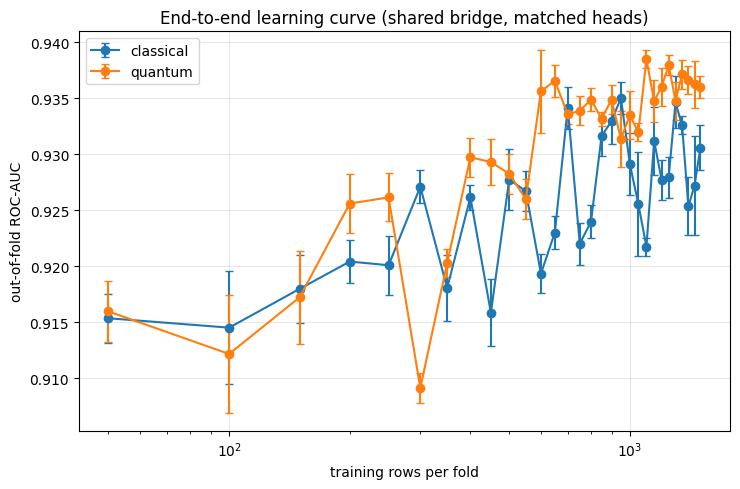

In [14]:
results = main_learning_curve()